# Sampling

## Setup

In [1]:
from pyDOE import lhs
from smt.sampling_methods import LHS
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from PIL import Image, ImageDraw
from ipywidgets import interact, IntSlider, fixed
import os
import cv2
import json
import seaborn as sns

In [2]:
def latin_hypercube_sum_constraint(n_samples, n_variables, sum_constraint,seed):
    # 1. Generate Latin Hypercube Samples
    if seed is not None:
        np.random.seed(seed)
    lhs_samples = lhs(n_variables, samples=n_samples, criterion='maximin')
    #sampling = LHS(xlimits=xlimits,random_state = np.random.RandomState(0))

    # 2. Transform samples to satisfy sum constraint
    for i in range(n_samples):
        current_sum = np.sum(lhs_samples[i, :])
        lhs_samples[i, :] *= sum_constraint / current_sum

    return lhs_samples

In [ ]:
# end conditions

## LHS

In [4]:
# seeds = [1,2,3,4,5]
seeds = [1]
arrays = []
n_samples = 8

for seed in seeds:
    df_lhs = pd.DataFrame(
        latin_hypercube_sum_constraint(
            n_samples=n_samples,
            n_variables=4,
            sum_constraint=270.0,
            seed=seed
        ),
        columns=["C", "M", "Y", "K"],
    )
    arrays.append(df_lhs.to_numpy().T)

CMYK_values = []

for i, array in enumerate(arrays):
    seed_value = seeds[i]
    
    c_values_str = ", ".join(map(str, array[0]))
    m_values_str = ", ".join(map(str, array[1]))
    y_values_str = ", ".join(map(str, array[2]))
    k_values_str = ", ".join(map(str, array[3]))

    print(f"Results for seed {seed_value}:")
    print("C (blue) values:")
    print(c_values_str)
    print("\nM (red) values:")
    print(m_values_str)
    print("\nY (yellow) values:")
    print(y_values_str)
    print("\nK (black) values:")
    print(k_values_str)
    print("\n" + "-"*50 + "\n")

    CMYK_values.append({
        "Results for seed": seed_value,
        "C (blue) values": c_values_str,
        "M (red) values": m_values_str,
        "Y (yellow) values": y_values_str,
        "K (black) values": k_values_str
    })

with open("CMYK_values.json", "w") as f:
    json.dump(CMYK_values, f, indent=2)

Results for seed 1:
C (blue) values:
32.70559840366913, 97.59323331796845, 68.99239840624564, 7.887770793637806, 59.497681932221674, 172.53467194394005, 28.642748207450367, 85.64920418928037

M (red) values:
107.50286277426395, 81.23789690652443, 17.060869216999055, 13.62459159767195, 128.013489465258, 63.70115225093016, 113.86329554321938, 57.26121332305052

Y (yellow) values:
72.50545544682114, 41.20774501453708, 95.04025946442957, 134.26181881925555, 76.87536151287757, 0.002869765097959732, 60.42469883588295, 17.51537959705464

K (black) values:
57.286083375245774, 49.96112476097003, 88.90647291232578, 114.22581878943474, 5.6134670896427386, 33.76130604003185, 67.06925741344733, 109.57420289061447

--------------------------------------------------



## Run Opentron

## Connect to Arducam

# Optimization

## Run CV

In [37]:
# image_path = '../../Arducam/captured_image.png'
image_path = 'v3_acrylic_purple.jpg'

def load_image(image_path):
    # Load and convert the image to RGB if not already in that mode
    image = Image.open(image_path).convert("RGB")
    return image
def display_image_with_pixel_value(image_path, x, y):
    # Load the image
    image = load_image(image_path)
    # Convert image to array for display purposes
    image_array = np.array(image)
    # Get the RGB value at the selected coordinates
    rgb_value = image.getpixel((x, y))
    # Create a copy of the image to draw the red dot
    draw = ImageDraw.Draw(image)
    dot_radius = 5
    draw.ellipse((x - dot_radius, y - dot_radius, x + dot_radius, y + dot_radius), fill='red', outline='red')
    # Display the image with the red dot
    plt.figure(figsize=(6,6))  # Optional: Set figure size
    plt.imshow(image)
    plt.axis('on')
    plt.title(f'RGB value at ({x}, {y}): {rgb_value}')

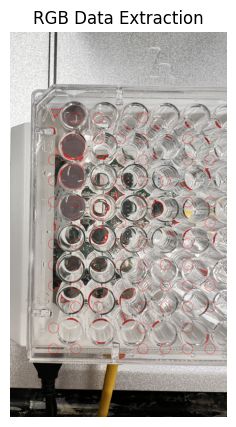

In [38]:
# Parameters for bilateral filter
diameter = 5
sigmaColor = 75
sigmaSpace = 75

# Load the image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
image = cv2.bilateralFilter(image, diameter, sigmaColor, sigmaSpace)
image_rgb = cv2.imread(image_path)

# Apply thresholding to isolate wells
ret, thresh = cv2.threshold(image, 127, 255, cv2.THRESH_BINARY_INV)

# Find contours of the wells
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Helper function to get the centroid y-coordinate of a contour
def get_contour_centroid(contour):
    M = cv2.moments(contour)
    if M["m00"] != 0:
        return (int(M["m10"] / M["m00"]), int(M["m01"] / M["m00"]))
    return (0, 0)

# Function to calculate circularity
def calculate_circularity(contour):
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    if perimeter == 0:
        return 0
    return (4 * np.pi * area) / (perimeter**2)

# Filter contours by area and circularity
contour_plot = []
rgb_values = []

# Minimum area to consider a contour valid
min_area = 900

# Circularity threshold for filtering
min_circularity = 0.17  # Adjust as needed (closer to 1 means stricter filtering)

for contour in contours:
    area = cv2.contourArea(contour)
    if area < min_area:
        continue  # Skip small contours

    circularity = calculate_circularity(contour)
    if circularity < min_circularity:
        continue  # Skip non-circular contours

    contour_plot.append(contour)

# vertical orientation
rows, cols = 12, 8
# horizontal
# rows, cols = 8, 12

num_required_contours = rows * cols

# Find bounding box for the detected contours
if contour_plot:
    x, y, w, h = cv2.boundingRect(np.vstack(contour_plot))
else:
    x, y, w, h = 0, 0, image_rgb.shape[1], image_rgb.shape[0]

grid_w, grid_h = w / cols, h / rows

# Organize contours into a sorted grid
grid = [[None for _ in range(cols)] for _ in range(rows)]
for contour in contour_plot:
    centroid = get_contour_centroid(contour)
    grid_x = int((centroid[0] - x) / grid_w)
    grid_y = int((centroid[1] - y) / grid_h)
    if 0 <= grid_x < cols and 0 <= grid_y < rows:
        grid[grid_y][grid_x] = contour

# Fill empty grid cells with artificial contours and compute RGB
for row_idx, row in enumerate(grid):
    for col_idx, contour in enumerate(row):
        if contour is None:
            # Add artificial contours for empty cells
            grid_x = int(x + col_idx * grid_w + grid_w / 2)
            grid_y = int(y + row_idx * grid_h + grid_h / 2)
            radius = int(min(grid_w, grid_h) / 4)
            synthetic_contour = np.array(
                [[grid_x + radius * np.cos(theta), grid_y + radius * np.sin(theta)]
                 for theta in np.linspace(0, 2 * np.pi, 20)],
                dtype=np.int32
            )
            mask = np.zeros(image_rgb.shape[:2], dtype="uint8")
            cv2.circle(mask, (grid_x, grid_y), radius, 255, -1)
            mean_val = cv2.mean(image_rgb, mask=mask)[:3]
            rgb_values.append(mean_val[::-1])  # RGB from BGR
            grid[row_idx][col_idx] = synthetic_contour
        else:
            # Compute RGB for real contours
            mask = np.zeros(image_rgb.shape[:2], dtype="uint8")
            cv2.drawContours(mask, [contour], -1, 255, -1)
            mean_val = cv2.mean(image_rgb, mask=mask)[:3]
            rgb_values.append(mean_val[::-1])  # RGB from BGR

# Draw the final contours
output_image = image_rgb.copy()
for row in grid:
    for contour in row:
        cv2.drawContours(output_image, [contour], -1, (0, 0, 255), 2)

output_image_rgb = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)  # Convert to RGB for matplotlib

# Display the results
plt.figure(figsize=(6, 5))
plt.imshow(output_image_rgb)
plt.axis('off')  # Hide axis
plt.title('RGB Data Extraction')
plt.show()

# Verify the top-left circle's RGB value
# print("Top-left RGB value:", rgb_values[0])

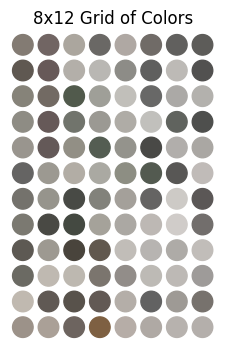

In [39]:
# Create a figure and axis
fig, ax = plt.subplots(figsize=(6, 4))

# Ensure we have exactly rows * cols colors
if len(rgb_values) < rows * cols:
    # Fill with black if not enough colors
    rgb_values += [[0, 0, 0]] * (rows * cols - len(rgb_values))

# Plot the grid of circles
for row in range(rows):
    for col in range(cols):
        index = row * cols + col
        rgb = rgb_values[index]
        color = [val / 255 for val in rgb]  # Normalize RGB values to [0, 1] range
        circle = plt.Circle((col + 0.5, rows - row - 0.5), 0.4, color=color)
        ax.add_patch(circle)

# Set the limits and adjust aspect ratio
ax.set_xlim(0, cols)
ax.set_ylim(0, rows)
ax.set_aspect('equal')
ax.axis('off')  # Remove axes

# Display the plot
plt.title('8x12 Grid of Colors')
plt.show()

## Converge BO

## RGB to CMYK

## Next iteration